# Machine Learning No Supervisado — Parte 1: Clustering (K-means y Clustering Jerárquico)

**Autor:** Harold Steven Rueda Lara · Universidad de Cundinamarca, Extensión Facatativá

**Objetivo.** Aplicar los algoritmos de *clustering* K-means y jerárquico aglomerativo con Scikit-learn sobre conjuntos de datos reales, elegir el número de grupos con criterios objetivos, visualizar los resultados con Matplotlib y analizarlos.

**Datos.** *Iris* (150 flores, 4 variables, 3 especies) y *Wine* (178 vinos, 13 variables químicas, 3 cultivares). Ambos vienen incluidos en `sklearn.datasets`, por lo que el notebook corre en Google Colab sin subir archivos.

**Nota metodológica.** Los algoritmos nunca ven las etiquetas reales (especie o cultivar). Estas se usan únicamente al final, como referencia externa, para medir qué tan bien coinciden los grupos encontrados con la clasificación real (índice de Rand ajustado, ARI).

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Liberation Serif', 'Times New Roman', 'DejaVu Serif'],
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})
os.makedirs('figuras', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

SEED = 42          # semilla para que los resultados sean reproducibles
metricas = {}      # aquí se guardan las métricas que luego se usan en el informe
MARCADORES = ['o', 's', '^', 'D', 'v']

from sklearn.datasets import load_iris, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

## 1. Carga y exploración de los datos (Iris)

In [2]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target
especies = iris.target_names

print('Dimensiones:', X_iris.shape)
print('Valores faltantes:', int(X_iris.isna().sum().sum()))
X_iris.describe().round(2)

Dimensiones: (150, 4)
Valores faltantes: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


Las variables están en la misma unidad (cm), pero tienen escalas distintas. Como K-means y el clustering jerárquico se basan en distancias, se **estandarizan** las variables (media 0 y desviación 1) para que ninguna domine el cálculo.

In [3]:
Xs_iris = StandardScaler().fit_transform(X_iris)
print('Medias:', Xs_iris.mean(axis=0).round(2), '| Desv.:', Xs_iris.std(axis=0).round(2))

Medias: [-0. -0. -0. -0.] | Desv.: [1. 1. 1. 1.]


## 2. K-means: elección del número de clusters (*k*)

Se usan dos criterios: el **método del codo** (inercia, es decir, la suma de distancias cuadráticas de cada punto a su centroide) y el **coeficiente de silueta** (cohesión frente a separación; va de −1 a 1, y valores más altos indican mejores grupos).

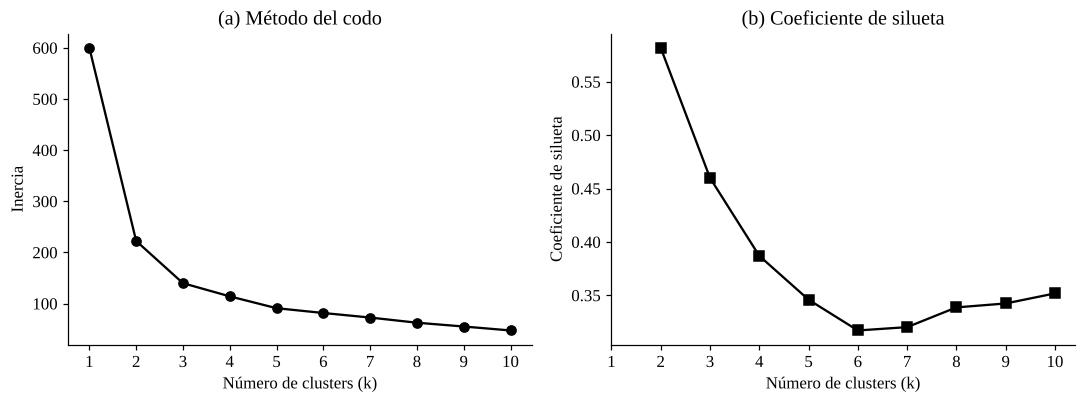

 k  inercia  silueta
 1   600.00      NaN
 2   222.36    0.582
 3   139.82    0.460
 4   114.09    0.387
 5    90.93    0.346
 6    81.54    0.317
 7    72.63    0.320
 8    62.54    0.339
 9    55.12    0.342
10    47.39    0.352


In [4]:
rango_k = range(1, 11)
inercia, silueta = [], []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs_iris)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Xs_iris, km.labels_) if k > 1 else np.nan)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(list(rango_k), inercia, marker='o', color='black')
ax[0].set_xlabel('Número de clusters (k)'); ax[0].set_ylabel('Inercia')
ax[0].set_title('(a) Método del codo')
ax[1].plot(list(rango_k), silueta, marker='s', color='black')
ax[1].set_xlabel('Número de clusters (k)'); ax[1].set_ylabel('Coeficiente de silueta')
ax[1].set_title('(b) Coeficiente de silueta')
for a in ax: a.set_xticks(list(rango_k))
plt.tight_layout()
plt.savefig('figuras/fig1_codo_silueta_iris.png', dpi=200, bbox_inches='tight')
plt.show()

tabla_k = pd.DataFrame({'k': list(rango_k), 'inercia': np.round(inercia, 2), 'silueta': np.round(silueta, 3)})
print(tabla_k.to_string(index=False))
metricas['iris_elección_k'] = tabla_k.to_dict(orient='list')

## 3. K-means con *k* = 3 sobre Iris

Aunque la silueta puede sugerir otro valor, se usa *k* = 3 y se compara con las tres especies reales para analizar la diferencia. Para poder dibujar los grupos en 2D, los datos de 4 variables se proyectan con PCA (la técnica se explica en el notebook 2); **el clustering se hace con las 4 variables originales estandarizadas**, no con la proyección.

K-means (k=3) en Iris -> ARI = 0.620 | silueta = 0.460
Inercia final: 139.82 | iteraciones: 4

Tabla de contingencia (filas = especie real, columnas = cluster):
Cluster      0   1   2
Especie               
setosa       0  50   0
versicolor  39   0  11
virginica   14   0  36


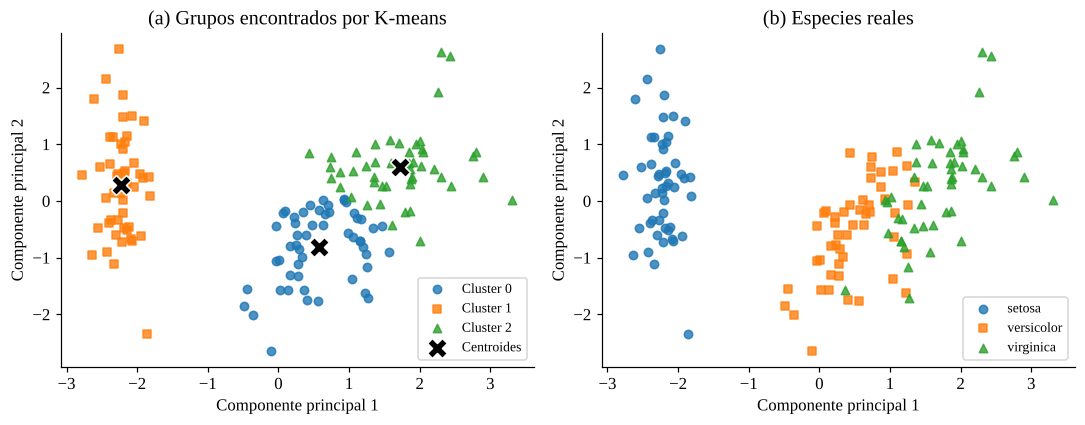

In [5]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xs_iris)
etiq_km = km3.labels_

ari_km = adjusted_rand_score(y_iris, etiq_km)
sil_km = silhouette_score(Xs_iris, etiq_km)
print(f'K-means (k=3) en Iris -> ARI = {ari_km:.3f} | silueta = {sil_km:.3f}')
print('Inercia final:', round(km3.inertia_, 2), '| iteraciones:', km3.n_iter_)
metricas['iris_kmeans'] = {'ari': ari_km, 'silueta': sil_km, 'inercia': km3.inertia_}

print()
print('Tabla de contingencia (filas = especie real, columnas = cluster):')
print(pd.crosstab(pd.Series(especies[y_iris], name='Especie'), pd.Series(etiq_km, name='Cluster')))

pca_vis = PCA(n_components=2, random_state=SEED)
Z = pca_vis.fit_transform(Xs_iris)
cent = pca_vis.transform(km3.cluster_centers_)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for c in range(3):
    ax[0].scatter(Z[etiq_km == c, 0], Z[etiq_km == c, 1], marker=MARCADORES[c], s=30, label=f'Cluster {c}', alpha=0.8)
    ax[1].scatter(Z[y_iris == c, 0], Z[y_iris == c, 1], marker=MARCADORES[c], s=30, label=especies[c], alpha=0.8)
ax[0].scatter(cent[:, 0], cent[:, 1], marker='X', s=170, c='black', edgecolor='white', label='Centroides')
ax[0].set_title('(a) Grupos encontrados por K-means')
ax[1].set_title('(b) Especies reales')
for a in ax:
    a.set_xlabel('Componente principal 1'); a.set_ylabel('Componente principal 2'); a.legend(fontsize=9)
plt.tight_layout()
plt.savefig('figuras/fig2_kmeans_iris.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Clustering jerárquico aglomerativo sobre Iris

El método parte de cada observación como su propio grupo y fusiona sucesivamente los dos grupos más cercanos. El resultado es un **dendrograma**: cortarlo a una altura determinada produce el número de clusters deseado. Se usa el enlace de **Ward**, que en cada paso minimiza el aumento de varianza dentro de los grupos.

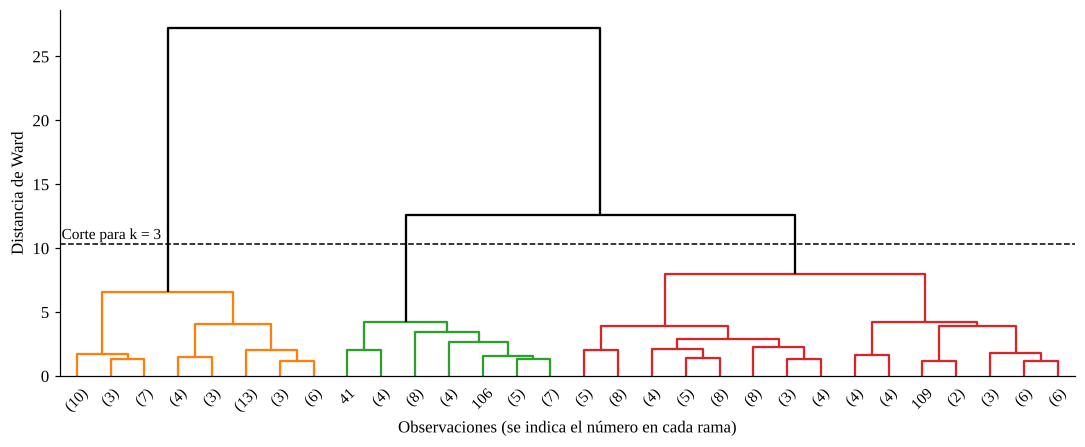

In [6]:
enlace = linkage(Xs_iris, method='ward')
altura_corte = (enlace[-3, 2] + enlace[-2, 2]) / 2   # corte que deja 3 clusters

fig, ax = plt.subplots(figsize=(10, 4.2))
dendrogram(enlace, truncate_mode='lastp', p=30, show_leaf_counts=True,
           color_threshold=altura_corte, above_threshold_color='black', ax=ax)
ax.axhline(altura_corte, color='black', linestyle='--', linewidth=1)
ax.text(0.5, altura_corte + 0.4, 'Corte para k = 3', fontsize=10)
ax.set_xlabel('Observaciones (se indica el número en cada rama)')
ax.set_ylabel('Distancia de Ward')
plt.tight_layout()
plt.savefig('figuras/fig3_dendrograma_iris.png', dpi=200, bbox_inches='tight')
plt.show()

### 4.1 Comparación de criterios de enlace

In [7]:
filas = []
for metodo in ['ward', 'complete', 'average', 'single']:
    etiq = AgglomerativeClustering(n_clusters=3, linkage=metodo).fit_predict(Xs_iris)
    filas.append({'Enlace': metodo,
                  'ARI': round(adjusted_rand_score(y_iris, etiq), 3),
                  'Silueta': round(silhouette_score(Xs_iris, etiq), 3),
                  'Tamaños': sorted(np.bincount(etiq).tolist(), reverse=True)})
comp_enlaces = pd.DataFrame(filas)
print(comp_enlaces.to_string(index=False))
metricas['iris_enlaces'] = comp_enlaces.to_dict(orient='records')

etiq_ward = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(Xs_iris)
print()
print('Tabla de contingencia (Ward, k=3):')
print(pd.crosstab(pd.Series(especies[y_iris], name='Especie'), pd.Series(etiq_ward, name='Cluster')))

  Enlace   ARI  Silueta      Tamaños
    ward 0.615    0.447 [71, 49, 30]
complete 0.573    0.450 [77, 49, 24]
 average 0.562    0.480  [97, 50, 3]
  single 0.558    0.505 [100, 49, 1]

Tabla de contingencia (Ward, k=3):
Cluster      0   1   2
Especie               
setosa       0  49   1
versicolor  23   0  27
virginica   48   0   2


## 5. Segundo conjunto de datos: Wine (13 variables) y el efecto de estandarizar

En Wine las variables tienen escalas muy distintas (por ejemplo, la prolina va de cientos a más de mil unidades y los fenoles totales están entre 1 y 4). Se ejecuta K-means con y sin estandarización para ver la consecuencia.

In [8]:
wine = load_wine(as_frame=True)
X_wine, y_wine = wine.data, wine.target
cultivares = np.array(['Cultivar 1', 'Cultivar 2', 'Cultivar 3'])   # clases 0, 1 y 2 del dataset
print('Dimensiones:', X_wine.shape)
X_wine[['proline', 'total_phenols', 'alcohol']].describe().round(2)

Dimensiones: (178, 13)


,proline,total_phenols,alcohol
count,178.00,178.00,178.00
mean,746.89,2.30,13.00
std,314.91,0.63,0.81
min,278.00,0.98,11.03
25%,500.50,1.74,12.36
50%,673.50,2.36,13.05
75%,985.00,2.80,13.68
max,1680.00,3.88,14.83


Sin estandarizar  -> ARI = 0.371 | silueta (en su espacio) = 0.571
Estandarizado     -> ARI = 0.897 | silueta (en su espacio) = 0.285
Jerárquico Ward (estandarizado) -> ARI = 0.790 | silueta = 0.277

Contingencia K-means sin estandarizar:
Cluster      0   1   2
Cultivar              
Cultivar 1  13  46   0
Cultivar 2  20   1  50
Cultivar 3  29   0  19

Contingencia K-means estandarizado:
Cluster      0   1   2
Cultivar              
Cultivar 1   0   0  59
Cultivar 2  65   3   3
Cultivar 3   0  48   0


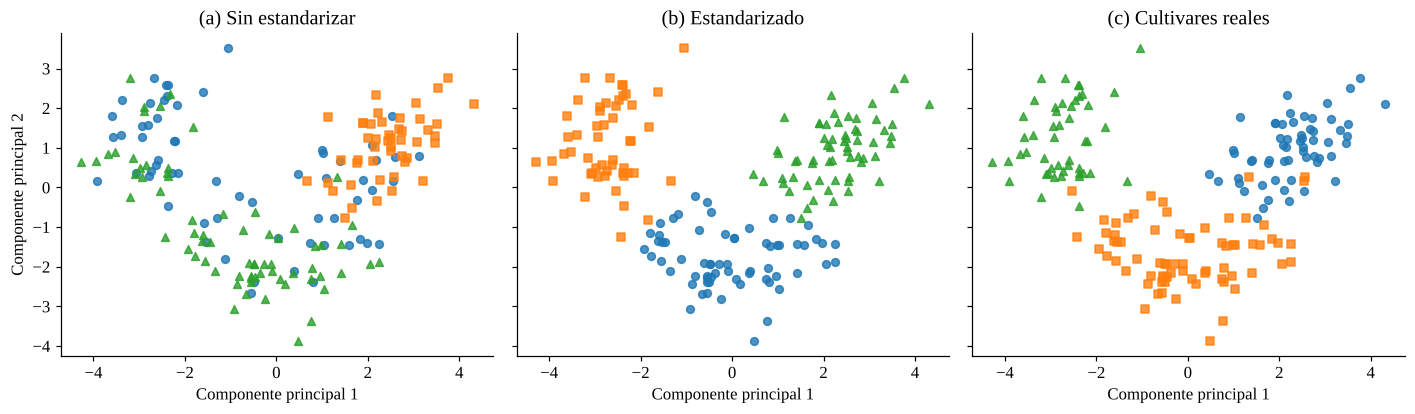

In [9]:
Xs_wine = StandardScaler().fit_transform(X_wine)

res = {}
for nombre, datos in [('Sin estandarizar', X_wine.values), ('Estandarizado', Xs_wine)]:
    km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(datos)
    res[nombre] = km.labels_
    print(f'{nombre:17s} -> ARI = {adjusted_rand_score(y_wine, km.labels_):.3f} | '
          f'silueta (en su espacio) = {silhouette_score(datos, km.labels_):.3f}')

# Jerárquico (Ward) sobre datos estandarizados
etiq_wine_h = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(Xs_wine)
print(f'Jerárquico Ward (estandarizado) -> ARI = {adjusted_rand_score(y_wine, etiq_wine_h):.3f} | '
      f'silueta = {silhouette_score(Xs_wine, etiq_wine_h):.3f}')

metricas['wine'] = {
    'kmeans_sin_estandarizar': {'ari': adjusted_rand_score(y_wine, res['Sin estandarizar']),
                                'silueta': silhouette_score(X_wine.values, res['Sin estandarizar'])},
    'kmeans_estandarizado': {'ari': adjusted_rand_score(y_wine, res['Estandarizado']),
                             'silueta': silhouette_score(Xs_wine, res['Estandarizado'])},
    'jerarquico_ward': {'ari': adjusted_rand_score(y_wine, etiq_wine_h),
                        'silueta': silhouette_score(Xs_wine, etiq_wine_h)},
}

print()
print('Contingencia K-means sin estandarizar:')
print(pd.crosstab(pd.Series(cultivares[y_wine], name='Cultivar'), pd.Series(res['Sin estandarizar'], name='Cluster')))
print()
print('Contingencia K-means estandarizado:')
print(pd.crosstab(pd.Series(cultivares[y_wine], name='Cultivar'), pd.Series(res['Estandarizado'], name='Cluster')))

# Visualización en el mismo plano PCA (calculado con los datos estandarizados)
Zw = PCA(n_components=2, random_state=SEED).fit_transform(Xs_wine)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), sharex=True, sharey=True)
paneles = [('(a) Sin estandarizar', res['Sin estandarizar']),
           ('(b) Estandarizado', res['Estandarizado']),
           ('(c) Cultivares reales', y_wine)]
for a, (tit, et) in zip(ax, paneles):
    for c in range(3):
        a.scatter(Zw[et == c, 0], Zw[et == c, 1], marker=MARCADORES[c], s=26, alpha=0.8)
    a.set_title(tit); a.set_xlabel('Componente principal 1')
ax[0].set_ylabel('Componente principal 2')
plt.tight_layout()
plt.savefig('figuras/fig4_wine_estandarizacion.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Análisis de resultados

**Elección de *k* en Iris.** La curva de inercia no muestra un codo definido: baja con fuerza de *k* = 1 a 3 (de 600,0 a 139,8) y luego de forma gradual. La silueta es máxima en *k* = 2 (0,582) y cae a 0,460 en *k* = 3. Geométricamente, Iris tiene dos nubes bien separadas: *setosa* por un lado y *versicolor* con *virginica* mezcladas por el otro. Usar *k* = 3 responde a un conocimiento previo del dominio (hay tres especies), no a un criterio interno de los datos.

**K-means (*k* = 3).** Aísla *setosa* sin errores (50 de 50). Se equivoca entre las otras dos especies: 11 *versicolor* y 14 *virginica* quedan en el cluster contrario, lo que da un ARI de 0,620. Es coherente con el gráfico: esas dos especies se solapan en el espacio de las variables.

**Clustering jerárquico.** El dendrograma muestra que la fusión más costosa (distancia de Ward ≈ 27) separa dos grandes ramas, lo que coincide con la silueta de *k* = 2. Cortado en *k* = 3, Ward obtiene un ARI de 0,615, casi igual al de K-means. Los enlaces `single` y `average` obtienen siluetas mayores (0,505 y 0,480), pero a costa de clusters degenerados (tamaños 100/49/1 y 97/50/3): un grupo contiene una o tres observaciones. Por eso una silueta alta no basta; conviene revisar también el tamaño de los grupos. Ward y `complete` producen grupos más equilibrados.

**Efecto de la estandarización (Wine).** Sin estandarizar, K-means obtiene un ARI de 0,371; estandarizado, 0,897 (172 de 178 vinos en el grupo correcto). La causa es que la prolina, con valores de cientos a más de mil, domina el cálculo de distancias frente a variables con rangos de 1 a 4. Además, la silueta sin estandarizar (0,571) es *mayor* que con estandarización (0,285) aunque los grupos son peores: mide separación a lo largo de una sola variable dominante, no la estructura real. En Wine, K-means (0,897) superó a Ward (0,790).

**Limitaciones.** K-means supone grupos compactos y de forma aproximadamente esférica, necesita fijar *k* de antemano y depende de la inicialización (se mitigó con `n_init=10` y semilla fija). Las métricas externas (ARI) solo se pueden calcular aquí porque se conocen las etiquetas reales; en un problema no supervisado real habría que apoyarse en criterios internos y en la interpretación de los grupos.

In [10]:
with open('resultados/metricas_clustering.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2, default=float)
print('Métricas guardadas en resultados/metricas_clustering.json')

Métricas guardadas en resultados/metricas_clustering.json
